In [1]:
# import a pickle file and see what it is inside
import pickle
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import cv2
# import deeplabcut as dlc
from scipy.io import loadmat
from sympy.printing.pretty.pretty_symbology import line_width

session = r'241125_2'
model_path = r'G:\My Drive\_Code\DLC-models\monocular-calibration-2024-11-26\videos'
model_name = r'DLC_Resnet50_monocularNov26shuffle1_snapshot_010'
data_path = r'D:\data-distance-coding-project\calibration'
data_path = os.path.join(data_path, session)

# import also the video file and extract the frames
video_filename = session + '.mp4'
df_filename = session + model_name + '.h5'

In [2]:
# now extract the frames
cap = cv2.VideoCapture(os.path.join(data_path, video_filename))
video_frames = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    video_frames.append(frame)
cap.release()

# in the data folder there is a matlab file
frame_filename = session + '_timestamps.mat'
frame_timestamp = loadmat(os.path.join(data_path, frame_filename))
frame_timestamp = frame_timestamp['frame_timestamp'][0]
frame_timestamp = frame_timestamp[frame_timestamp != 0]
frame_timestamp = np.insert(frame_timestamp, 0, 0)

data_filename = session + '_stim.mat'
data = loadmat(os.path.join(data_path, data_filename))
steps = data['stim_data']['steps'][0][0][0]
time = data['stim_data']['time'][0][0][0]
distance = data['stim_data']['distance_vec'][0][0][0]

# interpolate frame_timestamp to time and steps
frame_steps = np.interp(frame_timestamp - 0.28, time/1000, steps)

In [3]:
# in the data_path directory, create a folder called frames_snapsoths and save the frames in video_frames as jpeg
# files
temp_path = os.path.join(data_path, 'frames_snapshots')
if not os.path.exists(temp_path):
    os.makedirs(temp_path)

for idx, frame in enumerate(video_frames):
    frame_path = os.path.join(temp_path, 'frame_' + str(idx) + '.jpeg')
    cv2.imwrite(frame_path, frame)

In [4]:
def import_data_frame(filename):

    df = pd.read_hdf(filename)
    df.columns = df.columns.droplevel(0)

    return df

In [5]:
df = import_data_frame(os.path.join(model_path, df_filename))

Button(description='Reset Points', style=ButtonStyle())

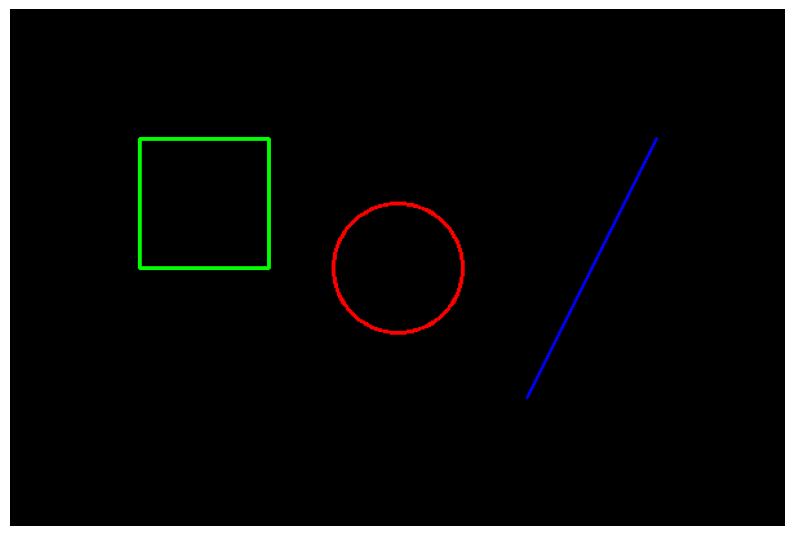

In [1]:
import cv2
import numpy as np
from IPython.display import display, Image
from IPython.display import clear_output
import ipywidgets as widgets
import matplotlib.pyplot as plt
%matplotlib inline

class ImagePointSelector:
    def __init__(self):
        self.image = None
        self.clone = None
        self.points = []
        self.fig = None
        self.ax = None

    def select_image(self, image_path):
        # Load the image
        self.image = cv2.imread(image_path)
        self.image = cv2.cvtColor(self.image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
        self.clone = self.image.copy()

        # Create the figure and connect the click event
        self.fig, self.ax = plt.subplots(figsize=(10, 8))
        self.ax.imshow(self.image)
        self.ax.axis('off')

        # Connect the click event
        self.cid = self.fig.canvas.mpl_connect('button_press_event', self.click_event)

        # Create reset button
        self.reset_button = widgets.Button(description='Reset Points')
        self.reset_button.on_click(self.reset_points)
        display(self.reset_button)

        plt.show()

    def click_event(self, event):
        if event.inaxes == self.ax:
            x, y = int(event.xdata), int(event.ydata)
            self.points.append((x, y))

            # Update the plot
            self.ax.clear()
            self.ax.imshow(self.image)

            # Plot all points
            points = np.array(self.points)
            if len(points) > 0:
                self.ax.scatter(points[:, 0], points[:, 1], c='red', s=50)

                # Add coordinate labels
                for i, (x, y) in enumerate(self.points):
                    self.ax.annotate(f'({x}, {y})', (x + 5, y + 5))

            self.ax.axis('off')
            plt.draw()

            # Print the coordinates
            print(f"Point {len(self.points)}: ({x}, {y})")

    def reset_points(self, _):
        self.points = []
        self.ax.clear()
        self.ax.imshow(self.image)
        self.ax.axis('off')
        plt.draw()
        print("Points reset")

    def get_points(self):
        return self.points

# Example usage
def create_test_image(filename='test_image.png'):
    # Create a test image
    test_image = np.zeros((400, 600, 3), dtype=np.uint8)  # Black background
    cv2.rectangle(test_image, (100, 100), (200, 200), (0, 255, 0), 2)  # Green rectangle
    cv2.circle(test_image, (300, 200), 50, (0, 0, 255), 2)  # Red circle
    cv2.line(test_image, (400, 300), (500, 100), (255, 0, 0), 2)  # Blue line
    cv2.imwrite(filename, test_image)
    return filename

# Create and use the selector
selector = ImagePointSelector()

# Create test image and start the selector
test_image_path = create_test_image()
selector.select_image(test_image_path)

In [ ]:
import cv2
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
%matplotlib inline

class ImagePointSelector:
    def __init__(self):
        self.points = []

    def select_points(self, image_path):
        # Read image
        img = cv2.imread(image_path)
        if img is None:
            print(f"Error: Could not load image from {image_path}")
            return

        # Convert BGR to RGB for matplotlib
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Display image
        plt.figure(figsize=(10, 8))
        plt.imshow(img)
        selected_points = plt.ginput(n=-1, timeout=0)  # Collect points until 'Enter' is pressed
        plt.close()

        # Store points as integers
        self.points = [(int(x), int(y)) for x, y in selected_points]

        # Display result with points
        plt.figure(figsize=(10, 8))
        plt.imshow(img)
        if self.points:
            points = np.array(self.points)
            plt.scatter(points[:, 0], points[:, 1], c='red', s=50)
            for i, (x, y) in enumerate(self.points, 1):
                plt.annotate(f'{i}: ({x}, {y})', (x + 5, y + 5))
        plt.axis('off')
        plt.show()

        # Print coordinates
        print("\nSelected points:")
        for i, (x, y) in enumerate(self.points, 1):
            print(f"Point {i}: ({x}, {y})")

    def get_points(self):
        return self.points

# Create a test image
def create_test_image(filename='test_image.png'):
    test_image = np.zeros((400, 600, 3), dtype=np.uint8)
    cv2.rectangle(test_image, (100, 100), (200, 200), (0, 255, 0), 2)
    cv2.circle(test_image, (300, 200), 50, (0, 0, 255), 2)
    cv2.line(test_image, (400, 300), (500, 100), (255, 0, 0), 2)
    cv2.imwrite(filename, test_image)
    return filename

# Usage example
selector = ImagePointSelector()
test_image_path = create_test_image()
selector.select_points(test_image_path)

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_31240\201458493.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  selected_points = plt.ginput(n=-1, timeout=0)  # Collect points until 'Enter' is pressed


In [ ]:
import cv2
import numpy as np
import matplotlib
matplotlib.use('Agg')  # Set backend before importing pyplot
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import ipyevents
from ipywidgets import Image as ipyImage
import ipywidgets as widgets

class ImagePointSelector:
    def __init__(self):
        self.points = []
        self.image = None
        self.current_display = None

    def show_image_with_points(self):
        # Create a copy of the image
        display_img = self.image.copy()

        # Draw points and coordinates
        for i, (x, y) in enumerate(self.points, 1):
            # Draw point
            cv2.circle(display_img, (x, y), 3, (255, 0, 0), -1)
            # Draw label
            cv2.putText(display_img, f'{i}: ({x},{y})', (x + 5, y + 5),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

        # Convert BGR to RGB for display
        display_img = cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB)

        # Clear previous output and show updated image
        clear_output(wait=True)
        plt.figure(figsize=(10, 8))
        plt.imshow(display_img)
        plt.axis('off')
        plt.show()

In [ ]:
import cv2
import numpy as np
import matplotlib
matplotlib.use('Agg')  # Set backend before importing pyplot
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import ipyevents
from ipywidgets import Image as ipyImage
import ipywidgets as widgets

class ImagePointSelector:
    def __init__(self):
        self.points = []
        self.image = None
        self.current_display = None

    def show_image_with_points(self):
        # Create a copy of the image
        display_img = self.image.copy()

        # Draw points and coordinates
        for i, (x, y) in enumerate(self.points, 1):
            # Draw point
            cv2.circle(display_img, (x, y), 3, (255, 0, 0), -1)
            # Draw label
            cv2.putText(display_img, f'{i}: ({x},{y})', (x + 5, y + 5),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

        # Convert BGR to RGB for display
        display_img = cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB)

        # Clear previous output and show updated image
        clear_output(wait=True)
        plt.figure(figsize=(10, 8))
        plt.imshow(display_img)
        plt.axis('off')
        plt.show()

In [ ]:
import cv2
import tkinter as tk
from tkinter import filedialog
import numpy as np

class ImagePointSelector:
    def __init__(self):
        self.image = None
        self.clone = None
        self.points = []
        self.window_name = "Image Point Selector"

    def select_image(self):
        # Create a temporary Tkinter window for file dialog
        root = tk.Tk()
        root.withdraw()  # Hide the Tkinter window

        # Open file dialog
        file_path = filedialog.askopenfilename(
            filetypes=[("Image files", "*.png *.jpg *.jpeg *.bmp")]
        )

        if file_path:
            # Load the image
            self.image = cv2.imread(file_path)
            self.clone = self.image.copy()

            # Create window and set mouse callback
            cv2.namedWindow(self.window_name)
            cv2.setMouseCallback(self.window_name, self.click_event)

            while True:
                # Display the image
                cv2.imshow(self.window_name, self.image)

                key = cv2.waitKey(1) & 0xFF

                # 'r' to reset
                if key == ord('r'):
                    self.image = self.clone.copy()
                    self.points = []

                # 'q' to quit
                elif key == ord('q'):
                    break

            # Clean up
            cv2.destroyAllWindows()

    def click_event(self, event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN:
            # Store the coordinates
            self.points.append((x, y))

            # Draw point on image
            cv2.circle(self.image, (x, y), 3, (0, 0, 255), -1)

            # Add coordinate text
            text = f"({x}, {y})"
            cv2.putText(self.image, text, (x + 10, y),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

            # Print coordinates to console
            print(f"Point {len(self.points)}: ({x}, {y})")

            # Refresh the display
            cv2.imshow(self.window_name, self.image)

def main():
    app = ImagePointSelector()
    app.select_image()

    # Print all points at the end
    if app.points:
        print("\nAll selected points:")
        for i, (x, y) in enumerate(app.points, 1):
            print(f"Point {i}: ({x}, {y})")

if __name__ == "__main__":
    main()# Goal: to get the points from an image instead of the dataframe

In [ ]:
import cv2
import numpy as np

# First, let's create a simple test image
test_image = np.zeros((400, 600, 3), dtype=np.uint8)  # Black background

# Add some shapes to make it easier to select points
cv2.rectangle(test_image, (100, 100), (200, 200), (0, 255, 0), 2)  # Green rectangle
cv2.circle(test_image, (300, 200), 50, (0, 0, 255), 2)  # Red circle
cv2.line(test_image, (400, 300), (500, 100), (255, 0, 0), 2)  # Blue line

# Save the test image
cv2.imwrite('test_image.png', test_image)

# Now let's use our ImagePointSelector
from image_point_selector import ImagePointSelector  # Assuming previous code is saved as image_point_selector.py

def run_test():
    print("Test Instructions:")
    print("1. When the file dialog opens, select 'test_image.png'")
    print("2. Click on different points in the image")
    print("3. Press 'r' to reset points")
    print("4. Press 'q' to quit")

    # Create and run the point selector
    selector = ImagePointSelector()
    selector.select_image()

    # Print final results
    if selector.points:
        print("\nFinal selected points:")
        for i, (x, y) in enumerate(selector.points, 1):
            print(f"Point {i}: ({x}, {y})")

if __name__ == "__main__":
    run_test()

In [48]:
def get_DLC_points(dataframe, idx=0):

    if idx not in dataframe['center']['x'].index:
        return None, None, None, None, None
    if idx not in dataframe['up']['x'].index:
        return None, None, None, None, None
    if idx not in dataframe['right']['x'].index:
        return None, None, None, None, None
    if idx not in dataframe['down']['x'].index:
        return None, None, None, None, None
    if idx not in dataframe['left']['x'].index:
        return None, None, None, None, None

    up = np.array([dataframe['up']['x'][idx], dataframe['up']['y'][idx]])
    right = np.array([dataframe['right']['x'][idx], dataframe['right']['y'][idx]])
    bottom = np.array([dataframe['down']['x'][idx], dataframe['down']['y'][idx]])
    left = np.array([dataframe['left']['x'][idx], dataframe['left']['y'][idx]])
    center = np.array([dataframe['center']['x'][idx], dataframe['center']['y'][idx]])

    return center, up, right, bottom, left

def get_ellipse_axes(dataframe, idx=0):

    center, up, right, bottom, left = get_DLC_points(dataframe, idx)

    if up is None:
        return None, None, None

    # get the major axis and minor axis
    vertical_distance = np.linalg.norm(up - bottom)
    horizontal_distance = np.linalg.norm(right - left)

    # for the horizontal axis, get the rotation
    theta = np.arctan2(right[1] - left[1], right[0] - left[0])

    return vertical_distance, horizontal_distance, theta

def get_ellipse_coordinates(dataframe, idx=0):

    if idx not in dataframe['center']['x'].index:
        return None, None

    center = get_DLC_points(dataframe, idx)[0]
    vertical_distance, horizontal_distance, theta = get_ellipse_axes(dataframe, idx)

    t = np.linspace(0, 2 * np.pi, 100)
    x = center[0] + (horizontal_distance / 2) * np.cos(theta) * np.cos(t) - (vertical_distance / 2) * np.sin(theta) * np.sin(t)
    y = center[1] + (horizontal_distance / 2) * np.sin(theta) * np.cos(t) + (vertical_distance / 2) * np.cos(theta) * np.sin(t)

    return x, y

def rotate_image(image, angle):
  image_center = tuple(np.array(image.shape[1::-1]) / 2)
  rot_mat = cv2.getRotationMatrix2D(image_center, angle, 1.0)
  result = cv2.warpAffine(image, rot_mat, image.shape[1::-1], flags=cv2.INTER_LINEAR)
  return result

def get_points_enclosed_by_ellipse(dataframe, video_frames, idx, show=False, quadrant=1):

    img = video_frames[idx]
    img_to_show = img.copy()

    x, y = get_ellipse_coordinates(dataframe, idx)
    center = get_DLC_points(dataframe, idx)[0]

    if x is None:
        return None

    xy_ellipse = np.array([x, y]).T

    # mask the image by the points given in pts_ellipse
    mask = np.zeros_like(img)
    cv2.fillPoly(mask, [xy_ellipse.astype(int)], (255, 255, 255))
    mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)

    # mask img by mask
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Set the values outside the mask to NaN
    image_masked = img.copy().astype(float)
    image_masked[mask == 0] = np.nan

    if quadrant is not None:

        x_center = center[0]
        y_center = center[1]

        # get vertical axis
        theta = get_ellipse_axes(dataframe, idx)[2]

        # rotate the image by theta
        image_masked = rotate_image(image_masked, theta)

        if quadrant == 1:
            image_masked[:, :x_center.astype(int)] = np.nan
            image_masked[y_center.astype(int):, :] = np.nan

        elif quadrant == 2:
            image_masked[:, x_center.astype(int):] = np.nan
            image_masked[y_center.astype(int):, :] = np.nan

        elif quadrant == 3:
            image_masked[:, x_center.astype(int):] = np.nan
            image_masked[:y_center.astype(int), :] = np.nan

        elif quadrant == 4:
            image_masked[:, :x_center.astype(int)] = np.nan
            image_masked[:y_center.astype(int), :] = np.nan

    values = image_masked[~np.isnan(image_masked)].flatten()

    if show:
        plt.figure()
        plt.imshow(image_masked, cmap='gray')
        plt.imshow(img_to_show, alpha=0.1, cmap='gray')
        plt.plot(xy_ellipse[:, 0], xy_ellipse[:, 1], 'r')

    return values

def get_features_of_ellipse(dataframe, video_frames, idx):


    x, y = get_ellipse_coordinates(dataframe, idx)
    xy_ellipse = np.array([x, y]).T

    bright_values = [get_points_enclosed_by_ellipse(dataframe, video_frames, idx, show=False, quadrant=2),
                     get_points_enclosed_by_ellipse(dataframe, video_frames, idx, show=False, quadrant=4)]
    dark_values = [get_points_enclosed_by_ellipse(dataframe, video_frames, idx, show=False, quadrant=1),
                   get_points_enclosed_by_ellipse(dataframe, video_frames, idx, show=False, quadrant=3)]

    bright_median = np.median(np.concatenate(bright_values))
    dark_median = np.median(np.concatenate(dark_values))

    features['bright_median'] = bright_median
    features['dark_median'] = dark_median
    features['area_region'] = cv2.contourArea(np.array(xy_ellipse).astype(int))

    return xy_ellipse, features

def compute_area(dataframe, video_frames, idx=0):

    values = get_points_enclosed_by_ellipse(dataframe, video_frames, idx, quadrant=None)

    if values is None:
        return None
    else:
        return len(values)


def write_ellipse_video(dataframe, video_frames):

    # Initialize the video writer
    frame_rate = 10  # Frames per second
    frame_width, frame_height = np.size(video_frames[0], 1), np.size(video_frames[0], 0)  # Resolution of the video
    video_out = cv2.VideoWriter(data_path + 'annotated_ellipse_moving.mp4', cv2.VideoWriter_fourcc(*'mp4v'), frame_rate, (frame_width, frame_height))

    # Create the animation and save each frame to the video
    num_frames = np.size(video_frames, 0)  # Number of frames in the video

    fig, ax = plt.subplots()
    plot_frame_with_ellipse(dataframe, video_frames, ax, 0)

    for i in range(150, 200):
        # print the frame number in the same line
        print('Frame number ' + str(i), end='\r')

        capture_frame(dataframe, video_frames, ax, video_out, fig, i)

    # Release the video writer and close the plot
    video_out.release()
    plt.close()

def plot_frame_with_ellipse(dataframe, video_frames, ax, frame):
    # Create the plot
    ax.clear()

    center, up, right, bottom, left = get_DLC_points(dataframe, frame)

    # now plot the actual frame
    ax.imshow(video_frames[frame])

    if center is not None:

        x, y = get_ellipse_coordinates(dataframe, frame)

        # Plot contour of ellipse
        ax.plot(x, y, 'b-', label='Ellipse')
        ax.fill(x, y, 'y', alpha=0.1)

        # Plot points
        ax.plot(center[0], center[1], 'ro', label='Center')
        ax.plot(up[0], up[1], 'go', label='Up')
        ax.plot(right[0], right[1], 'go', label='Right')
        ax.plot(bottom[0], bottom[1], 'go', label='Bottom')
        ax.plot(left[0], left[1], 'go', label='Left')

        # Plot axes
        ax.plot([left[0], right[0]], [left[1], right[1]], 'purple', linestyle='--', alpha=0.5)
        ax.plot([bottom[0], up[0]], [bottom[1], up[1]], 'purple', linestyle='--', alpha=0.5)

    # Add labels and grid
    ax.axis('image')
    # set axis off
    ax.axis('off')

# Function to capture the plot and convert it to an image
def capture_frame(dataframe, video_frames, ax, video_out, fig, frame):

    plot_frame_with_ellipse(dataframe, video_frames, ax, frame)
    plt.draw()

    frame_width, frame_height = np.size(video_frames[frame], 1), np.size(video_frames[frame], 0)

    # Convert the canvas to an image (RGB format)
    fig.canvas.draw()
    img = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
    img = img.reshape(fig.canvas.get_width_height()[::-1] + (3,))

    # Convert RGB to BGR (OpenCV format)
    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    # # Resize the image to match video resolution
    img_resized = cv2.resize(img_bgr, (frame_width, frame_height))

    # Write the frame to the video
    video_out.write(img_resized)


In [49]:
# write video
write_ellipse_video(df, video_frames)

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_12176\3518503378.py:216: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed two minor releases later. Use buffer_rgba instead.
  img = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)


# Control: Area

Text(0.5, 1.0, 'Retinal Size')

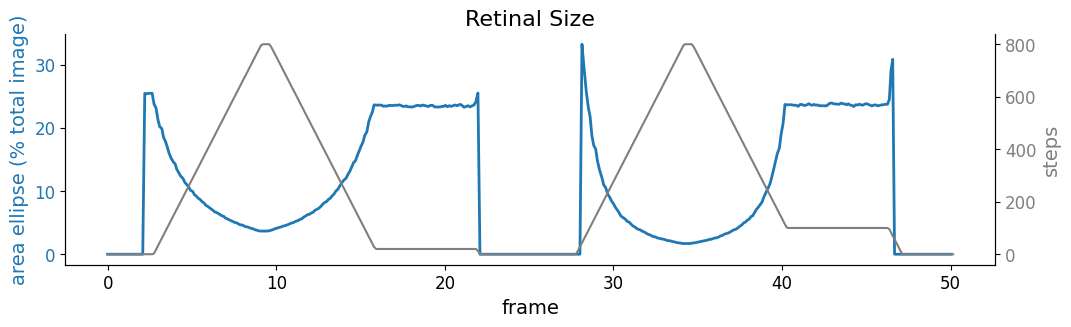

In [46]:
# compute area of the ellipse for all frames
area_ellipse = []
for idx in range(np.size(video_frames, 0)):
    area_frame = compute_area(df, video_frames, idx)
    if area_frame is not None:
        area_ellipse.append(area_frame)
    else:
        area_ellipse.append(0)

# area frame
area_frame = np.size(video_frames, 1) * np.size(video_frames, 2)
area_ellipse = 100 * np.array(area_ellipse) / area_frame
# plot the area of the ellipse and the steps in different y axis
fig, ax1 = plt.subplots(figsize=(12, 3))

color = 'tab:blue'
ax1.set_xlabel('frame', fontsize=14)
ax1.set_ylabel('area ellipse (% total image)', color=color, fontsize=14)

ax1.plot(frame_timestamp[:-1], area_ellipse, color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:gray'
ax2.set_ylabel('steps', color=color, fontsize=14)
ax2.plot(frame_timestamp, frame_steps, color=color)
ax2.tick_params(axis='y', labelcolor=color)

# remove line up
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

# set labels numbers to 12
ax1.xaxis.set_tick_params(labelsize=12)
ax1.yaxis.set_tick_params(labelsize=12)
ax2.yaxis.set_tick_params(labelsize=12)

# set title
plt.title('Retinal Size', fontsize=16)
#


# Control: Angle

Text(0.5, 1.0, 'Vertical Orientation')

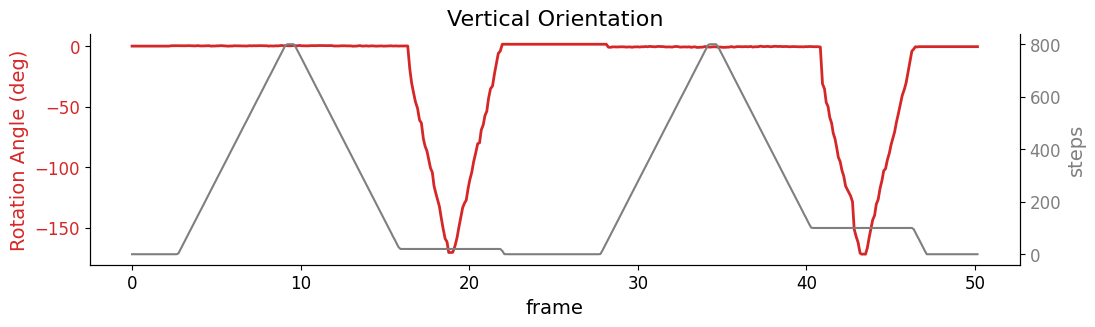

In [45]:
# calculate theta for all frames
theta_video = [0]
for idx in range(np.size(video_frames, 0)):
    _, _, theta = get_ellipse_axes(df, idx)
    if theta is not None:
        theta_video.append(theta)
    else:
        theta_video.append(theta_video[-1])

fig, ax1 = plt.subplots(figsize=(12, 3))

color = 'tab:red'
ax1.set_xlabel('frame', fontsize=14)
ax1.set_ylabel('Rotation Angle (deg)', color=color, fontsize=14)

ax1.plot(frame_timestamp, np.degrees(theta_video), color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:gray'
ax2.set_ylabel('steps', color=color, fontsize=14)
ax2.plot(frame_timestamp, frame_steps, color=color)
ax2.tick_params(axis='y', labelcolor=color)

# remove line up
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

# set labels numbers to 12
ax1.xaxis.set_tick_params(labelsize=12)
ax1.yaxis.set_tick_params(labelsize=12)
ax2.yaxis.set_tick_params(labelsize=12)

# set title
plt.title('Vertical Orientation', fontsize=16)

# Control: Luminance

Text(0.5, 1.0, 'Luminance')

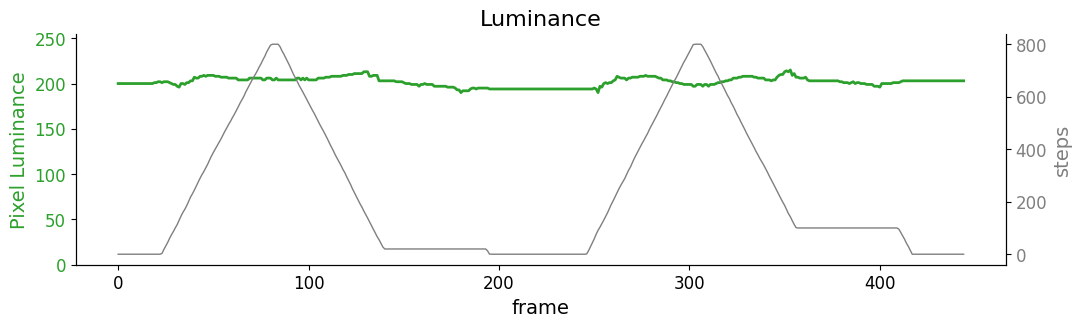

In [47]:
# calculate theta for all frames
values_frames = [200]
for idx in range(np.size(video_frames, 0)):
    values = get_points_enclosed_by_ellipse(df, video_frames, idx, show=False, quadrant=None)
    if values is not None:
        values = values[values>100]
        values_frames.append(np.median(values))
    else:
        values_frames.append(values_frames[-1])

fig, ax1 = plt.subplots(figsize=(12, 3))

color = 'tab:green'
ax1.set_xlabel('frame', fontsize=14)
ax1.set_ylabel('Pixel Luminance', color=color, fontsize=14)
ax1.set_ylim([0, 255])

ax1.plot(values_frames, color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:gray'
ax2.set_ylabel('steps', color=color, fontsize=14)
ax2.plot(frame_steps, color=color, linewidth=1)
ax2.tick_params(axis='y', labelcolor=color)

# remove line up
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

# set labels numbers to 12
ax1.xaxis.set_tick_params(labelsize=12)
ax1.yaxis.set_tick_params(labelsize=12)
ax2.yaxis.set_tick_params(labelsize=12)

# set title
plt.title('Luminance', fontsize=16)